<a href="https://colab.research.google.com/github/prabhnoor14/walmart-hurricane-project/blob/main/notebooks/2026-10-23%20%E2%80%94%20Midterm%20Checkpoint%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Checkpoint

**Lab — 2026-10-23 · Fall 2026**  

---

## Lab 09 — Midterm checkpoint, week 1 of 3

**What you submit: the link to your team's main repo. Only that.** One submission per team. Do not upload separate files.

Put this notebook in the repo (the `notebooks/` folder is fine) and push it, so everything we check is in one place.

**You do not have to fill this all out.** It is a checkpoint, not a finished project. Skip any section you have not started and write "not started" next to it. What we must see is:

1. **Your charter**, committed to the repo
2. **Any progress** you have made, with code that ran and output you can point at

Start with the team setup, then work down the same eight things we listed at Monday's kickoff, as far as you have gotten. This is graded on evidence, not on intentions.

The purpose is to catch a stalled team while there is still time to unstall it. If something is not working, say so here plainly. A checkpoint that honestly reports "the API join is not working and here is the error" is worth more than one that claims progress that does not exist, and it gets you help on Monday.

### Team setup

This part is required. Fill it in once for the whole team.

You need:

- Your team name, and every member with a GitHub handle (2 to 4 people)
- A link to your team's **main repo**. This is the one link you submit.
- A link to `CHARTER.md` in that repo, the page on GitHub, not a file on someone's laptop

Nice to have, and also in your charter: this week's notebook owner, your meeting time, and the five worst problems in the data from the profile you ran on Monday. Be specific: "`unit_price` is stored as text and some values start with `$`" beats "prices are messy."

In [1]:
team_setup = {
    'team_name': '1',
    'members': [                                  # everyone on the team, 2 to 4 people
        {'name': 'Safaa Mahbub', 'github': 'SafaaMahbub'},
        {'name': 'Norah Munoz', 'github': 'norahmunoz'},
        {'name': 'Samikksha Kumar', 'github': 'uyx7uy'},
        {'name': 'Prabhnoor Kaur ', 'github': 'prabhnoor14'},
    ],
    'repo_url': 'https://github.com/prabhnoor14/walmart-hurricane-project',                           # your main team repo: https://github.com/...
    'charter_url': 'https://github.com/prabhnoor14/walmart-hurricane-project/blob/main/CHARTER.md',                        # link to CHARTER.md in that repo
    'notebook_owner_this_week': 'Prabhnoor Kaur',           # nice to have
    'meeting_time': 'Mo,Wed,Fr: 9:00AM-10:00AM',                       # nice to have, e.g. 'Tue and Thu 7pm'
    'five_worst_problems': [    # nice to have, five specific problems
      'store_id is written 60 ways for 12 stores (FL-302, FL_302, fl-302, FL302, " FL-302")',
      'unit_price is stored as text and some values start with $',
      'timestamp uses mixed date formats and 886 rows are missing it',
      'category is written 37 ways for 10 categories (GROCERY, Groceries, grocery)',
      'the same product has several SKUs (Strawberry Pop-Tarts: PT-12, SKU#459812, PT_STRAWBERRY, POPTART-STRAW)',
      ],

}

def check_team(t, quiet=False):
    def real(v):
        return isinstance(v, str) and v.strip() != '' and not v.startswith('TODO')
    required = {
        'team name': real(t['team_name']),
        '2 to 4 members, each with a name and GitHub handle':
            2 <= len(t['members']) <= 4 and all(real(m['name']) and real(m['github']) for m in t['members']),
        'main repo link': real(t['repo_url']) and t['repo_url'].startswith('https://github.com/'),
        'charter link points at CHARTER.md': real(t['charter_url']) and t['charter_url'].endswith('CHARTER.md'),
    }
    nice = {
        'notebook owner': real(t['notebook_owner_this_week']),
        'meeting time': real(t['meeting_time']),
        'five specific problems': len(t['five_worst_problems']) >= 5 and all(real(p) for p in t['five_worst_problems']),
    }
    if not quiet:
        print('REQUIRED')
        for label, good in required.items():
            print('  PASS' if good else '  FAIL', '-', label)
        print('NICE TO HAVE')
        for label, good in nice.items():
            print('  done' if good else '  not yet', '-', label)
        print()
        print('team setup complete:', all(required.values()))
    return all(required.values())

check_team(team_setup)

REQUIRED
  PASS - team name
  PASS - 2 to 4 members, each with a name and GitHub handle
  PASS - main repo link
  PASS - charter link points at CHARTER.md
NICE TO HAVE
  done - notebook owner
  done - meeting time
  done - five specific problems

team setup complete: True


True

Now show that the charter is actually committed. This is required. Run the next cell and leave its output in the notebook. Point `REPO_PATH` at your local clone of the team repo. If it prints a line like `a1b2c3d Add team charter`, you are done. If it prints "no commits found," the charter is not in the repo yet, so commit it and push before you submit.

In [2]:
!git clone https://github.com/prabhnoor14/walmart-hurricane-project

fatal: destination path 'walmart-hurricane-project' already exists and is not an empty directory.


In [3]:
import subprocess

REPO_PATH = './walmart-hurricane-project'      # your local clone of the team repo

result = subprocess.run(['git', '-C', REPO_PATH, 'log', '--oneline', '--', 'CHARTER.md'],
                        capture_output=True, text=True)
print(result.stdout.strip() or 'no commits found for CHARTER.md')

ae317e9 Update CHARTER.md
d7c67de Fix formatting issue in CHARTER.md
92efb64 Add Norah's focus on sales trends and geographic patterns
97536f7 Update CHARTER.md
af091ac Update CHARTER.md
f4dc619 Add meeting frequency during class to charter
feea4fc Update team member names in CHARTER.md
074a3a4 Expand CHARTER.md with work split and tasks
fc6834b Update CHARTER.md
9c1aa10 Expand project charter with detailed goals and communication
4f4a412 Update CHARTER.md
a5a8a88 Update CHARTER.md
cb4728b Add structure and roles to CHARTER.md
e902989 Create CHARTER.md


### 1 — Your cleaning pipeline as functions

**TODO:** paste the cleaning code you have written so far. It should be functions, not loose cells, and it should cover at minimum: duplicates, `unit_price` to numeric (it comes in as text, some with a `$`), the negative `quantity` values with your decision applied, `timestamp` parsed, and `store_id` cleaned up so it will join to the store file.

Print the row count before and after. We want to see how many rows your decisions removed.

In [4]:
Decisions = []

def log_decision( decision, row_affected):
  Decisions.append({'decision': decision, 'rows': row_affected})
  print(f'{decision}({row_affected} row(s))')
def show_log():
  return pd.DataFrame(Decisions)

In [5]:
import pandas as pd

def load_table(PATH):
  try:
      df = pd.read_csv(PATH)
      df.head()
      return df
  except FileNotFoundError:
      print('File not found. Please check the file exist or double check the path')
      return None
walmart_transactions = load_table('/content/walmart-hurricane-project/data/walmart_transactions.csv')
distribution_centers = load_table('/content/walmart-hurricane-project/data/distribution_centers.csv')
store_locations = load_table('/content/walmart-hurricane-project/data/store_locations.csv')
product_catalog = load_table('/content/walmart-hurricane-project/data/product_catalog.csv')

In [6]:
# TODO
#handling duplicates:
def drop_duplicate(frame):
  clean = frame.drop_duplicates().copy() # saving a copy of the frame after dropping duplicates to not alter the original frame
  print('rows:', len(frame), '->', len(clean))
  log_decision('LOG: dropping duplicated rows',len(frame)-len(clean))
  print('\n')
  return clean
print('Count of rows after dropping duplicated rows from the product_catalog table')
product_catalog_copy = drop_duplicate(product_catalog)
print('Count of rows after dropping duplicated rows from the walmart_transactions table')
walmart_transactions_copy = drop_duplicate(walmart_transactions)
print('Count of rows after dropping duplicated rows from the distribution_centers table')
distribution_centers_copy = drop_duplicate(distribution_centers)
print('Count of rows after dropping duplicated rows from the store_location table')
store_locations_copy = drop_duplicate(store_locations)

Count of rows after dropping duplicated rows from the product_catalog table
rows: 45 -> 45
LOG: dropping duplicated rows(0 row(s))


Count of rows after dropping duplicated rows from the walmart_transactions table
rows: 25562 -> 25532
LOG: dropping duplicated rows(30 row(s))


Count of rows after dropping duplicated rows from the distribution_centers table
rows: 5 -> 5
LOG: dropping duplicated rows(0 row(s))


Count of rows after dropping duplicated rows from the store_location table
rows: 14 -> 14
LOG: dropping duplicated rows(0 row(s))




In [7]:
#handling unit_price to numeric
def transform_price_columns(df, column_name):
  df[column_name] = (df[column_name].astype(str)
                     .str.replace('$','',regex=False)
                     .str.strip().astype(float))

  return df
transform_price_columns(walmart_transactions_copy, 'unit_price')
log_decision('tranforming unit_price column to numeric', len(walmart_transactions_copy['unit_price']))

tranforming unit_price column to numeric(25532 row(s))


In [8]:
#handling missing timestamp
def transform_missing_timestamp(df):
  df['timestamp'] = pd.to_datetime(df['timestamp'],errors='coerce', format ='mixed')
  missing_date = df['timestamp'].isna().sum()
  log_decision('Tranforming missing timestamps to NaT - rows affected: ', missing_date)
  df[df['timestamp'].isna()]
transform_missing_timestamp(walmart_transactions_copy)

Tranforming missing timestamps to NaT - rows affected: (884 row(s))


In [9]:
# Cleaning category names
def clean_categories(df):
    category_mapping = {
        'Alcoholic Beverages': 'Alcohol',
        'Baby Products': 'Baby',
        'Breakfast Foods': 'Breakfast',
        'Emergency Supplies': 'Emergency',
        'Games & Entertainment': 'Entertainment',
        'Groceries': 'Grocery',
        'Health & Wellness': 'Health',
        'Household Essentials': 'Household'
    }
    df['category'] = df['category'].str.strip().str.title()
    df['category'] = df['category'].replace(category_mapping)
    return df

walmart_transactions_copy = clean_categories(walmart_transactions_copy)
log_decision("Standardized Walmart categories and mapped 8 category names (pending team confirmation)", len(walmart_transactions_copy))
print(walmart_transactions_copy['category'].unique())

Standardized Walmart categories and mapped 8 category names (pending team confirmation)(25532 row(s))
['Grocery' 'Household' 'Electronics' 'Alcohol' 'Snacks' 'Emergency'
 'Entertainment' 'Health' 'Breakfast' 'Baby']


In [10]:
# Checking missing Walmart timestamps
def check_missing_timestamps(df):
    missing = df['timestamp'].isna().sum()
    print("Missing timestamps:", missing)
    print("Timestamp type:", df['timestamp'].dtype)
    return missing

missing = check_missing_timestamps(walmart_transactions_copy)
log_decision("Kept missing Walmart timestamps as NaT because original dates were missing", missing)

Missing timestamps: 884
Timestamp type: datetime64[ns]
Kept missing Walmart timestamps as NaT because original dates were missing(884 row(s))


In [11]:
# Setting sales timezone (pending team confirmation)
def set_sales_timezone(df):
    if df['timestamp'].dt.tz is None:
        df['timestamp'] = df['timestamp'].dt.tz_localize('America/New_York')
    return df

walmart_transactions_copy = set_sales_timezone(walmart_transactions_copy)
print("Sales timezone:", walmart_transactions_copy['timestamp'].dt.tz)
print("Missing timestamps:", walmart_transactions_copy['timestamp'].isna().sum())

Sales timezone: America/New_York
Missing timestamps: 884


In [12]:
# Documenting timezone assumption
log_decision("Assumed sales timestamps use Eastern Time (pending team confirmation)", walmart_transactions_copy['timestamp'].notna().sum())

Assumed sales timestamps use Eastern Time (pending team confirmation)(24648 row(s))


In [13]:
# Cleaning store IDs so the transactions join to the store file
def clean_store_id(col):
    col = col.astype(str).str.strip().str.upper().str.replace('_', '-', regex=False)
    number = col.str.replace('FL', '', regex=False).str.replace('-', '', regex=False)
    return 'FL-' + number



In [14]:
def apply_store_id_cleaning(tx, stores):
    print('store ids before:', tx['store_id'].nunique(), '(transactions),', stores['store_id'].nunique(), '(store file)')
    cleaned = clean_store_id(tx['store_id'])
    log_decision('Standardized transaction store ids to FL-### format', (tx['store_id'] != cleaned).sum())
    tx['store_id'] = cleaned

    cleaned = clean_store_id(stores['store_id'])
    log_decision('Standardized store_locations store ids to FL-### format', (stores['store_id'] != cleaned).sum())
    stores['store_id'] = cleaned
    print('store ids after: ', tx['store_id'].nunique(), '(transactions),', stores['store_id'].nunique(), '(store file)')
    return tx, stores

walmart_transactions_copy, store_locations_copy = apply_store_id_cleaning(walmart_transactions_copy, store_locations_copy)

store ids before: 60 (transactions), 14 (store file)
Standardized transaction store ids to FL-### format(4345 row(s))
Standardized store_locations store ids to FL-### format(2 row(s))
store ids after:  12 (transactions), 12 (store file)


In [15]:
# Cleaning the store file: duplicate stores, state names, missing coordinates
def clean_store_locations(stores):
    before = len(stores)
    stores = stores.drop_duplicates().reset_index(drop=True)
    print('store rows:', before, '->', len(stores))
    log_decision('Dropped duplicate store rows that matched after cleaning store ids', before - len(stores))

    state_map = {'Florida': 'FL', 'Fla.': 'FL'}
    log_decision('Changed state values Florida and Fla. to FL', stores['state'].isin(state_map.keys()).sum())
    stores['state'] = stores['state'].replace(state_map)

    # Tallahassee city center (30.4383, -84.2807), from findlatitudeandlongitude.com / worldatlas.com
    missing = stores['latitude'].isna() | stores['longitude'].isna()
    stores.loc[stores['store_id'] == 'FL-619', ['latitude', 'longitude']] = [30.4383, -84.2807]
    log_decision('Filled missing latitude/longitude for FL-619 with Tallahassee city-center coordinates', missing.sum())
    return stores

In [16]:
store_locations_copy = clean_store_locations(store_locations_copy)
# Checking that every transaction finds its store
def check_store_join(tx, stores):
    joined = tx.merge(stores, on='store_id', how='left')
    unmatched = joined['city'].isna().sum()
    print('rows before join:', len(tx), '| after:', len(joined), '| no matching store:', unmatched)

    assert len(stores) == 12, 'store file should have 12 stores'
    assert len(joined) == len(tx), 'join added rows, so a store is duplicated'
    assert unmatched == 0, 'some transactions have no matching store'
    return joined

joined = check_store_join(walmart_transactions_copy, store_locations_copy)

store rows: 14 -> 12
Dropped duplicate store rows that matched after cleaning store ids(2 row(s))
Changed state values Florida and Fla. to FL(3 row(s))
Filled missing latitude/longitude for FL-619 with Tallahassee city-center coordinates(1 row(s))
rows before join: 25532 | after: 25532 | no matching store: 0


Store IDs: There were 60 store IDs for 12 stores because each store was written 5 ways (FL-302, FL_302, fl-302, FL302, “ FL-302”). The function fixes all of them to FL-###. After that, 2 rows in the store file turned out to be the same store entered twice, so they were dropped. Florida/Fla. were changed to FL, and Tallahassee’s missing coordinates were filled with its city center, since the weather API needs them. The store file now joins to every transaction with no rows lost.

In [17]:
# Negative quantities: kept in the data
def flag_negative_quantities(tx):
    is_return = tx['quantity'] < 0
    tx['is_return'] = is_return
    print('rows before:', len(tx), '| rows after:', len(tx), '(nothing removed)')
    print('negative quantity rows kept and flagged:', is_return.sum())
    log_decision('Kept negative quantities and flagged them in is_return column (likely returns, pending team confirmation)', is_return.sum())
    return tx

walmart_transactions_copy = flag_negative_quantities(walmart_transactions_copy)

rows before: 25532 | rows after: 25532 (nothing removed)
negative quantity rows kept and flagged: 130
Kept negative quantities and flagged them in is_return column (likely returns, pending team confirmation)(130 row(s))


Negative quantities: 130 rows have a negative quantity. They were kept because they most likely show returns, and flagged in an is_return column so they can be filtered out later. This is an assumption.

### 2 — Your decision log

**TODO:** every cleaning decision, what it did, and how many rows it touched. If your teammates disagree with one of these, note the disagreement — that is useful information, not a problem to hide.

In [18]:
# TODO: print or display your decision log
show_log()

,decision,rows
0,LOG: dropping duplicated rows,0
1,LOG: dropping duplicated rows,30
2,LOG: dropping duplicated rows,0
3,LOG: dropping duplicated rows,0
4,tranforming unit_price column to numeric,25532
5,Tranforming missing timestamps to NaT - rows a...,884
6,Standardized Walmart categories and mapped 8 c...,25532
7,Kept missing Walmart timestamps as NaT because...,884
8,Assumed sales timestamps use Eastern Time (pen...,24648
9,Standardized transaction store ids to FL-### f...,4345


### 3 — SKU consolidation progress

**TODO:** how many distinct SKUs did you start with, how many canonical products do you have now, and what is your largest consolidated group? Show the mapping for at least one product family. Pop-Tarts is a good one to start with.

You do not need this finished — you need it started and defensible.

In [19]:
# TODO

### 4 — One working weather API call

**TODO:** show the call and the parsed DataFrame. It must include the retry logic and a `source` column. Say which timezone the weather timestamps are in and how you will line them up with the sales timestamps. If it is not working, paste the actual error and what you have tried.

In [20]:
# TODO
import requests
import time

url = 'https://archive-api.open-meteo.com/v1/archive'   # Open-Meteo Historical Weather API, no key needed

def get_weather(store_id, lat, lon, retries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': '2024-09-01', 'end_date': '2024-09-30',
        'daily': 'temperature_2m_max,precipitation_sum,wind_speed_10m_max',
        'hourly': 'pressure_msl',          # pressure is only available hourly
        'timezone': 'America/New_York'
    }
    for attempt in range(1, retries + 1):
        try:
            response = requests.get(url, params=params, timeout=30)
            response.raise_for_status()
            data = response.json()
            break
        except requests.RequestException as e:
            print(f'{store_id}: attempt {attempt} failed: {e}')
            if attempt == retries:
                raise
            time.sleep(2 * attempt)

    daily = pd.DataFrame(data['daily'])
    daily['date'] = pd.to_datetime(daily['time'])
    daily = daily.drop(columns='time')

    hourly = pd.DataFrame(data['hourly'])
    hourly['date'] = pd.to_datetime(hourly['time']).dt.normalize()
    pressure = hourly.groupby('date')['pressure_msl'].mean().reset_index(name='pressure_msl_mean')

    weather = daily.merge(pressure, on='date', how='left')
    weather['store_id'] = store_id
    weather['source'] = 'Open-Meteo archive API'
    return weather

# one working call: Orlando
orlando = get_weather('FL-239', 28.5383, -81.3792)
print(orlando.shape)
orlando.head()

(30, 7)


,temperature_2m_max,precipitation_sum,wind_speed_10m_max,date,pressure_msl_mean,store_id,source
0,30.8,6.4,18.7,2024-09-01,1014.100000,FL-239,Open-Meteo archive API
1,29.9,22.0,12.7,2024-09-02,1014.066667,FL-239,Open-Meteo archive API
2,31.0,32.7,20.6,2024-09-03,1015.558333,FL-239,Open-Meteo archive API
3,31.1,21.1,12.6,2024-09-04,1017.691667,FL-239,Open-Meteo archive API
4,31.6,20.7,15.2,2024-09-05,1017.291667,FL-239,Open-Meteo archive API


In [21]:
# Getting weather for every store
def get_all_weather(stores):
    all_weather = []
    for _, store in stores.iterrows():
        all_weather.append(get_weather(store['store_id'], store['latitude'], store['longitude']))
        time.sleep(1)   # short pause between calls

    weather = pd.concat(all_weather, ignore_index=True)
    print('weather rows:', len(weather), '| stores:', weather['store_id'].nunique())

    assert len(weather) == len(stores) * 30, 'expected 30 days per store'
    assert not weather.duplicated(['store_id', 'date']).any(), 'a store has the same day twice'
    return weather

weather = get_all_weather(store_locations_copy)

weather rows: 360 | stores: 12


Timezone: Open-Meteo returns times in UTC by default, so the call asks for America/New_York. Each daily value then covers an Eastern-time day, which matches the sales data (the brief says sales are in EST). To line them up, sales will be totaled per store per day and joined to the weather on store_id + date. Assumption: Pensacola (FL-710) is really on Central time, but its sales are treated as Eastern like the brief says.

Status: Working. The call retries up to 3 times if it fails, every row has a source column, and weather was pulled for all 12 stores (360 rows = 12 stores × 30 days) with no duplicate days.

In [22]:
log_decision('Pulled weather in America/New_York for all stores to match sales data, which the brief says is in EST (assumes Pensacola sales are also Eastern)', len(weather))

Pulled weather in America/New_York for all stores to match sales data, which the brief says is in EST (assumes Pensacola sales are also Eastern)(360 row(s))


### 5 — One chart

**TODO:** daily order volume across your date range. It does not need to be presentation quality yet, but it does need labeled axes and a title.

Look at it before you submit. Does the shape make sense? An early chart is the fastest way to catch a cleaning bug — if your daily volume has a day at zero or a day at ten times everything else, that is usually your pipeline, not the hurricane.

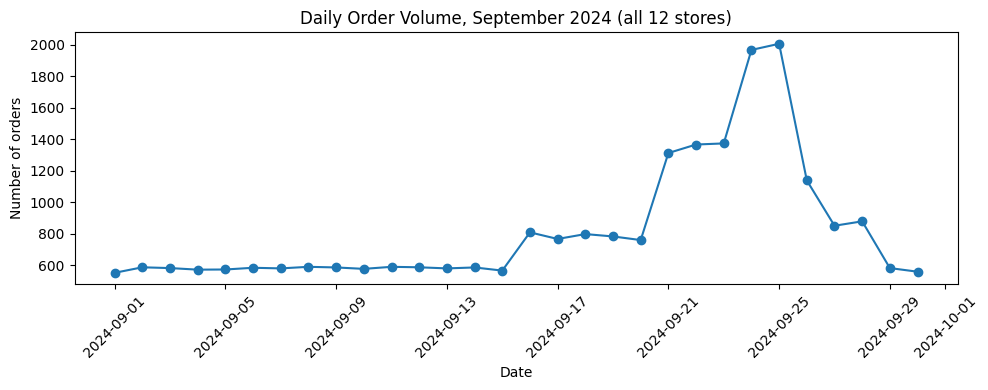

count      30.000000
mean      821.600000
std       401.920098
min       552.000000
25%       580.500000
50%       588.500000
75%       840.500000
max      2007.000000
Name: transaction_id, dtype: float64


In [23]:
# TODO
import matplotlib.pyplot as plt

# Daily order volume across September
def plot_daily_orders(tx):
    dated = tx.dropna(subset=['timestamp']).copy()
    dated['date'] = dated['timestamp'].dt.tz_localize(None).dt.normalize()
    daily_orders = dated.groupby('date')['transaction_id'].nunique()

    plt.figure(figsize=(10, 4))
    plt.plot(daily_orders.index, daily_orders.values, marker='o')
    plt.title('Daily Order Volume, September 2024 (all 12 stores)')
    plt.xlabel('Date')
    plt.ylabel('Number of orders')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    return daily_orders

daily_orders = plot_daily_orders(walmart_transactions_copy)
print(daily_orders.describe())

Daily order volume: Orders stay around 580 a day for the first half of September. They start going up on Sept 16, keep climbing, and peak at about 2,000 a day on Sept 24–25. After that they drop back down to normal by the end of the month. There aren’t any days at zero or random spikes, so the chart looks like a real buildup before the storm and not a cleaning mistake. Sales with no timestamp (884) aren’t included since they don’t have a date.

### 6 — Self-check

Fill in what you have and leave the rest. **The required items are the team setup and the charter.** Everything else is progress we want to see, not a pass or fail. The checks are shape checks; they cannot verify your analysis is right, only that you have gotten far enough to have one.

In [24]:
required = {
    'team_setup_complete': check_team(team_setup, quiet=True),   # from the team setup section
    'charter_committed': True,         # TODO: True once CHARTER.md shows in the git log above
}

progress = {
    'rows_after_cleaning': len(walmart_transactions_copy),        # an integer
    'decisions_logged': len(Decisions),           # how many entries in your log
    'canonical_products': None,         # distinct products after consolidation
    'weather_api_rows': len(weather),           # rows returned by your API call
    'notebook_runs_clean': False,       # True after Restart and Run All
}

def is_done(value):
    return not (value is None or value is False
                or (isinstance(value, str) and value.startswith('TODO')))

def check(required, progress):
    print('REQUIRED')
    for label, value in required.items():
        print('  PASS' if is_done(value) else '  FAIL', '-', label, '=', value)
    print('PROGRESS (fill in what you have)')
    for label, value in progress.items():
        print('  done' if is_done(value) else '  not yet', '-', label, '=', value)
    ok = all(is_done(v) for v in required.values())
    print()
    print('required items complete:', ok)
    print('progress items done:', sum(is_done(v) for v in progress.values()), 'of', len(progress))
    return ok

check(required, progress)

REQUIRED
  PASS - team_setup_complete = True
  PASS - charter_committed = True
PROGRESS (fill in what you have)
  done - rows_after_cleaning = 25532
  done - decisions_logged = 16
  not yet - canonical_products = None
  done - weather_api_rows = 360
  not yet - notebook_runs_clean = False

required items complete: True
progress items done: 3 of 5


True

### 7 — Risk and plan

Two questions, answered concretely.

**a)** What is the single most likely thing to go wrong in the next two weeks? Name a specific technical or team problem, not "running out of time."

**b)** What are you doing about it this week? Name who is doing it and by when.

**Biggest risk:** Merging SKUs that look the same but aren't. For example, one Strawberry Pop-Tarts SKU is a 6-pack and the others are 4-packs. If we merge products that are actually different, the Q2 numbers will be off.

**Plan, with an owner and a date:** When building the SKU mapping, anything where the pack size doesn't match gets flagged and not merged. The whole team goes over the flagged ones at the Wednesday, Oct 28 meeting and logs what we decide.

### 8 — Where each question stands

**TODO:** mark each of the five questions. These owners must match the question owners table in your charter. Be honest — this is the section I read first.

| Question | Status | Who owns it |
|---|---|---|
| Q1 demand surge | Not started (date and category cleaning completed) | _Norah_ |
| Q2 SKU consolidation | _..._ | _..._ |
| Q3 weather correlation |Not started on the analysis. Weather is ready: pulled for all 12 stores (360 rows). Next: join to daily sales, break sales down by category, then correlation and lag| Prabhnoor |
| Q4 store and geography | Not started | _Norah_ |
| Q5 signal or artifact | not started  | _..._ |

At the end of week 1, "not started" on Q4 and Q5 is expected. "Not started" on all five means come find me on Monday.